In [ ]:
# Cell 1: imports
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
import joblib

# plotting defaults
%matplotlib inline
plt.rcParams['figure.figsize'] = (10,5)
sns.set(style='whitegrid')


In [2]:
# Cell 2: load
df = pd.read_csv("D:/Projects/RockWatch/data/raw/master_log.csv")   # path to your master_log
df.shape, list(df.columns)[:30]      # quick confirm
df.head(6)

,global_hour,scenario_id,hour_in_scenario,rainfall_mm,temperature_C,vibration_hz,wind_speed_kmh,ground_saturation_pct,freeze_thaw_cycles,consecutive_rain_hours,...,weathering_factor,daily_max_temp,daily_min_temp,diurnal_range,simulated_RMR,simulated_discontinuity_score,simulated_slope_angle,LABEL,trigger_reason,image_file
0,1,1,1,0.0,1.0048,0,13.5836,0.0,0,0,...,0.99999,1.0,1.00,0.00,75.98,2,76.49,STABLE,No Trigger,img_h_000001.png
1,2,1,2,0.0,0.2556,0,9.3472,0.0,0,0,...,0.99998,1.0,0.26,0.75,75.98,2,76.49,STABLE,No Trigger,img_h_000002.png
2,3,1,3,0.0,0.0000,0,6.0116,0.0,0,0,...,0.99997,1.0,0.00,1.00,75.98,2,76.49,STABLE,No Trigger,img_h_000003.png
3,4,1,4,0.0,0.2556,0,8.9326,0.0,0,0,...,0.99996,1.0,0.00,1.00,75.98,2,76.49,STABLE,No Trigger,img_h_000004.png
4,5,1,5,0.0,1.0048,0,13.5710,0.0,0,0,...,0.99995,1.0,0.00,1.00,75.98,2,76.49,STABLE,No Trigger,img_h_000005.png
5,6,1,6,0.0,2.1967,0,13.6067,0.0,0,0,...,0.99994,2.2,0.00,2.20,75.98,2,76.49,STABLE,No Trigger,img_h_000006.png


In [3]:
# Cell 3: basic checks
print(df.dtypes)
print("Missing per column:\n", df.isna().sum().sort_values(ascending=False).head(20))
print("Duplicated rows:", df.duplicated().sum())
# If timestamp or datetime columns exist:
# df['timestamp'] = pd.to_datetime(df['timestamp'])  # if applicable


global_hour                        int64
scenario_id                        int64
hour_in_scenario                   int64
rainfall_mm                      float64
temperature_C                    float64
vibration_hz                       int64
wind_speed_kmh                   float64
ground_saturation_pct            float64
freeze_thaw_cycles                 int64
consecutive_rain_hours             int64
rainfall_intensity_mm_hr         float64
weathering_factor                float64
daily_max_temp                   float64
daily_min_temp                   float64
diurnal_range                    float64
simulated_RMR                    float64
simulated_discontinuity_score      int64
simulated_slope_angle            float64
LABEL                             object
trigger_reason                    object
image_file                        object
dtype: object
Missing per column:
 global_hour                      0
scenario_id                      0
hour_in_scenario                 0

In [ ]:
# Cell 4: categorical sanity checks
for col in ['LABEL','trigger_reason','trigger_event','scenario_id']:
    if col in df.columns:
        print(col, df[col].value_counts(dropna=False).to_dict())


LABEL {'STABLE': 5955, 'UNSTABLE': 15}
trigger_reason {'No Trigger': 3990, 'Post-Failure': 1965, 'Freeze-Thaw Threshold Met (Eff Thr: 1)': 5, 'Freeze-Thaw Threshold Met (Eff Thr: 2)': 4, 'Freeze-Thaw Threshold Met (Eff Thr: 3)': 3, 'Saturation Threshold Met (Eff Thr: 41.2)': 1, 'Saturation Threshold Met (Eff Thr: 52.0)': 1, 'Saturation Threshold Met (Eff Thr: 49.6)': 1}
scenario_id {1: 168, 30: 168, 20: 168, 21: 168, 22: 168, 27: 168, 28: 168, 29: 168, 31: 168, 18: 168, 32: 168, 33: 168, 34: 168, 35: 168, 36: 168, 37: 168, 2: 168, 19: 168, 17: 168, 16: 168, 3: 168, 4: 168, 5: 168, 6: 168, 7: 168, 8: 168, 9: 168, 10: 168, 11: 168, 12: 168, 13: 168, 14: 168, 15: 168, 38: 168, 26: 138, 23: 120}


In [4]:
# Cell 5: plausibility examples
g = 9.81

# Example 1: rainfall should be >=0
print("Negative rainfall count:", (df['rainfall_mm'] < 0).sum())

# Example 2: kinetic energy plausibility (if you have kinetic energy and seed height)
if {'simulated_mass','simulated_velocity','simulated_height'}.issubset(df.columns):
    # E_kinetic <= m*g*h + small tolerance
    E_kin = 0.5 * df['simulated_mass'] * df['simulated_velocity']**2
    E_pot = df['simulated_mass'] * g * df['simulated_height']
    df['E_kin'] = E_kin
    df['E_pot'] = E_pot
    print("kinetic > potential count:", (E_kin > E_pot * 1.05).sum())

# Example 3: saturations should be 0..100 or 0..1
print("saturation min/max:", df['ground_saturation_pct'].min(), df['ground_saturation_pct'].max())


Negative rainfall count: 0
saturation min/max: 0.0 100.0


In [5]:
# Cell 6: outliers using IQR for key numerical columns
num_cols = ['rainfall_mm','temperature_C','vibration_hz','wind_speed_kmh','ground_saturation_pct','freeze_thaw_cycles','simulated_discontinuity_score','simulated_RMR','simulated_slope_angle','simulated_RMR']
for c in num_cols:
    if c in df.columns:
        q1,q3 = df[c].quantile([0.25,0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
        out = df[(df[c] < lower)|(df[c] > upper)]
        print(c, "outliers:", len(out), f"range [{lower:.3g},{upper:.3g}]")


rainfall_mm outliers: 559 range [0,0]
temperature_C outliers: 0 range [-11.4,24.8]
vibration_hz outliers: 2 range [0,0]
wind_speed_kmh outliers: 127 range [-1.8,25.1]
ground_saturation_pct outliers: 1248 range [0,0]
freeze_thaw_cycles outliers: 672 range [-4.5,7.5]
simulated_discontinuity_score outliers: 0 range [-3,5]
simulated_RMR outliers: 0 range [14.7,97.4]
simulated_slope_angle outliers: 0 range [24.4,95.4]
simulated_RMR outliers: 0 range [14.7,97.4]


In [6]:
report = {
 "n_rows": len(df),
 "n_cols": len(df.columns),
 "missing_counts": df.isna().sum().to_dict(),
 "duplicates": int(df.duplicated().sum())
}
with open("data_quality_report.json","w") as f:
    json.dump(report,f,indent=2)
report


{'n_rows': 5970,
 'n_cols': 21,
 'missing_counts': {'global_hour': 0,
  'scenario_id': 0,
  'hour_in_scenario': 0,
  'rainfall_mm': 0,
  'temperature_C': 0,
  'vibration_hz': 0,
  'wind_speed_kmh': 0,
  'ground_saturation_pct': 0,
  'freeze_thaw_cycles': 0,
  'consecutive_rain_hours': 0,
  'rainfall_intensity_mm_hr': 0,
  'weathering_factor': 0,
  'daily_max_temp': 0,
  'daily_min_temp': 0,
  'diurnal_range': 0,
  'simulated_RMR': 0,
  'simulated_discontinuity_score': 0,
  'simulated_slope_angle': 0,
  'LABEL': 0,
  'trigger_reason': 0,
  'image_file': 0},
 'duplicates': 0}

## EDA

# Cell 8: distribution plots
num = df.select_dtypes(include=np.number).columns.tolist()
sns.histplot(df['rainfall_mm'], kde=True); plt.title("Rainfall distribution")
# loop small multiples
for c in ['vibration_hz','ground_saturation_pct','simulated_discontinuity_score','simulated_slope_angle']:
    if c in df.columns:
        plt.figure()
        sns.histplot(df[c].dropna(), kde=True)
        plt.title(c)


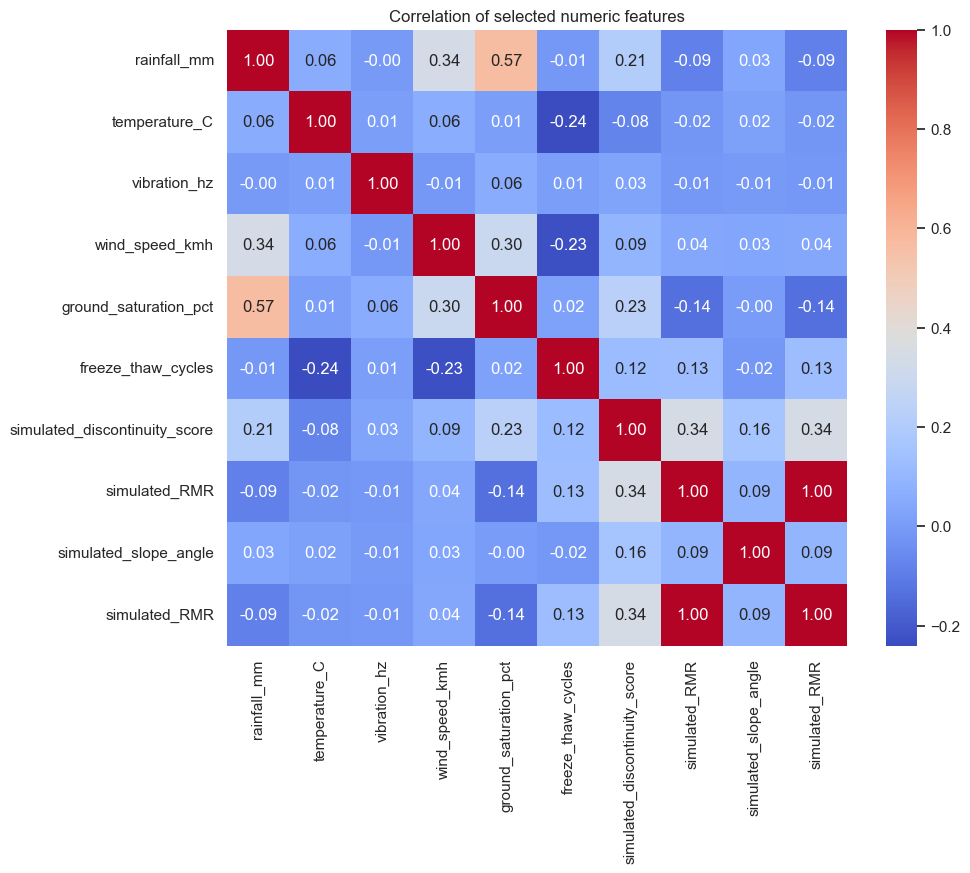

In [ ]:
# Cell 9: correlation matrix
corr = df[num_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation of selected numeric features")
plt.show()

In [ ]:
# Cell 10: slope_angle vs runout (if runout present)
if 'final_runout' in df.columns:
    sns.scatterplot(x='simulated_slope_angle', y='final_runout', hue='LABEL', data=df, alpha=0.6)
    plt.yscale('linear')
    plt.title("Slope Angle vs Final Runout by LABEL")
    plt.show()


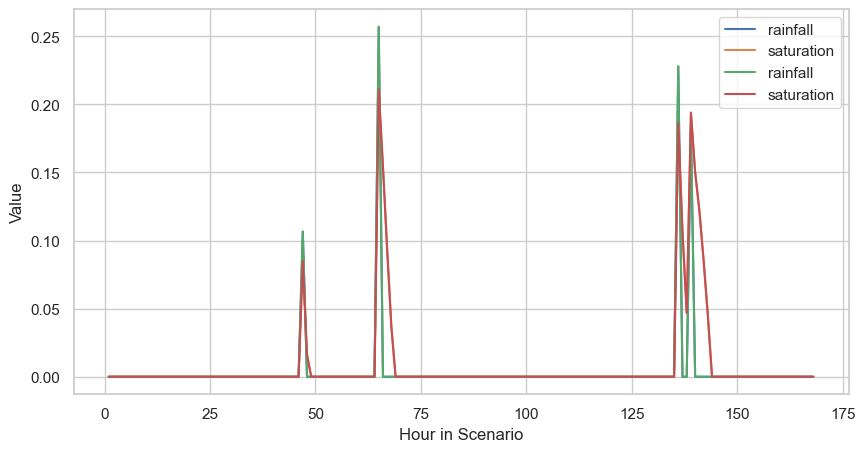

In [ ]:
# Cell 11: plot rainfall and saturation across hours for one scenario
s = df[df['scenario_id']==1]
plt.plot(s['hour_in_scenario'], s['rainfall_mm'], label='rainfall')
plt.plot(s['hour_in_scenario'], s['ground_saturation_pct'], label='saturation')
plt.legend()
plt.xlabel('Hour in Scenario')
plt.ylabel('Value')     
plt.show()

2) DATA TRANSFORMATION & FEATURE ENGINEERING

Use a modular function file preproc_utils.py (or notebook cells) and keep transformations reproducible.

Key derived features to create (domain-driven)

cum_rain_6h, cum_rain_24h, cum_rain_72h (rolling sums per scenario)

rainfall_intensity (rainfall_mm/hour) — if hours regularly spaced

temp_gradient = daily_max_temp - daily_min_temp or rolling gradient

sat_change_1h = current_saturation - previous hour saturation (per scenario)

vibration_peak = rolling max vibration over last N hours

slope_bin = bin(slope_angle, [60,65,70,75,80])

roughness_norm = scaled roughness measure

energy_ratio = kinetic_energy / potential_energy (if available)

is_freezing = temperature_C < 0 and freeze_thaw_cycles > 0

In [ ]:
# Cell 12: feature engineering (per scenario time-series)
df = df.sort_values(['scenario_id','hour_in_scenario']).reset_index(drop=True)

# rolling cumulative rainfall per scenario
df['cum_rain_6h'] = df.groupby('scenario_id')['rainfall_mm'].transform(lambda x: x.rolling(window=6, min_periods=1).sum())
df['cum_rain_24h'] = df.groupby('scenario_id')['rainfall_mm'].transform(lambda x: x.rolling(window=24, min_periods=1).sum())

# delta saturation (hour-over-hour)
df['sat_delta_1h'] = df.groupby('scenario_id')['ground_saturation_pct'].diff().fillna(0)

# temp gradient example (if daily max/min fields exist)
if 'daily_max_temp' in df.columns and 'daily_min_temp' in df.columns:
    df['temp_gradient'] = df['daily_max_temp'] - df['daily_min_temp']

# slope bins
df['slope_bin'] = pd.cut(df['simulated_slope_angle'], bins=[0,60,65,70,75,90], labels=['<60','60-65','65-70','70-75','75+'])

# energy ratio if fields exist (safety check)
if {'simulated_velocity','simulated_mass','simulated_height'}.issubset(df.columns):
    df['pot_energy'] = df['simulated_mass'] * 9.81 * df['simulated_height']
    df['kin_energy'] = 0.5 * df['simulated_mass'] * df['simulated_velocity']**2
    df['energy_ratio'] = df['kin_energy'] / (df['pot_energy'] + 1e-9)


In [ ]:
# Cell 13: fill/clip
# Example: saturation should be 0..100
df['ground_saturation_pct'] = df['ground_saturation_pct'].clip(lower=0, upper=100)

# Fill missing numeric with median (scenario-wise if appropriate)
for c in num_cols:
    if c in df.columns:
        df[c] = df[c].fillna(df.groupby('scenario_id')[c].transform('median')).fillna(df[c].median())

# Categorical fill
df['LABEL'] = df['LABEL'].fillna('UNKNOWN')


In [ ]:
# Cell 14: label encoding / one-hot examples
# If LABEL is target:
df['label_num'] = df['LABEL'].map({'STABLE':0,'UNSTABLE':1,'No Trigger':0,'Trigger':1}).fillna(0).astype(int)

# One-hot slope bin (for scikit-learn ColumnTransformer later)
df = pd.get_dummies(df, columns=['slope_bin'], prefix='slope')


## 3) PREPROCESSING PIPELINE

In [ ]:
import os

# Create artifacts directory if it doesn't exist
os.makedirs('artifacts', exist_ok=True)

# Your existing preprocessing code
# ...existing code...

# Save preprocessor
joblib.dump(preprocessor, "artifacts/preprocessor.joblib")

['artifacts/preprocessor.joblib']

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = ['rainfall_mm','cum_rain_24h','vibration_hz','ground_saturation_pct','simulated_discontinuity_score','simulated_RMR','temp_gradient']
cat_features = [c for c in ['slope_bin','trigger_reason'] if c in df.columns]

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
], remainder='drop')

# fit & save preprocessor on entire df (or training split only)
X = df[num_features + cat_features]
y = df['label_num']
preprocessor.fit(X)
joblib.dump(preprocessor, "artifacts/preprocessor.joblib")


['artifacts/preprocessor.joblib']

In [ ]:
# Cell 16: correlation check for num_features
plt.figure(figsize=(8,6))
sns.heatmap(df[num_features].corr().abs(), annot=True)
plt.title("Numeric features correlation (abs)")


Text(0.5, 1.0, 'Numeric features correlation (abs)')

In [ ]:
from sklearn.ensemble import RandomForestClassifier
X_tmp = preprocessor.transform(X)  # careful: this yields numpy array with transformed features
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_tmp, y)
importances = rf.feature_importances_
# map back to feature names
num_ohe_names = list(preprocessor.named_transformers_['cat']['ohe'].get_feature_names_out(cat_features)) if cat_features else []
feature_names = num_features + num_ohe_names
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
feat_imp.head(20).plot(kind='barh')


<Axes: title={'center': 'Numeric features correlation (abs)'}>